In [18]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [19]:
df = pd.read_csv('df_prep.csv').drop(columns='Unnamed: 0')

In [20]:
df.head(5)

,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,is_missing_Physical_Activitty,Stress_Level
0,22.0,Female,Science,2.90,7.3,3.3,3.4,114.0,0,5.0
1,20.0,Male,Engineering,2.72,5.5,7.2,6.0,74.0,1,2.0
2,20.0,Male,Medical,2.90,5.4,2.3,1.8,137.0,0,3.0
3,21.0,Male,Engineering,3.63,8.1,2.0,4.6,130.0,0,3.0
4,19.0,Male,Arts,3.14,6.8,2.6,4.3,4.0,0,6.0


In [21]:
df.shape

(100000, 10)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Age                            100000 non-null  float64
 1   Gender                         100000 non-null  object 
 2   Department                     100000 non-null  object 
 3   CGPA                           100000 non-null  float64
 4   Sleep_Duration                 100000 non-null  float64
 5   Study_Hours                    100000 non-null  float64
 6   Social_Media_Hours             100000 non-null  float64
 7   Physical_Activity              100000 non-null  float64
 8   is_missing_Physical_Activitty  100000 non-null  int64  
 9   Stress_Level                   100000 non-null  float64
dtypes: float64(7), int64(1), object(2)
memory usage: 7.6+ MB


### Separasi Fitur dan Target

In [23]:
X = df.drop(columns=['Stress_Level'])
y = df['Stress_Level']

### Separasi Kolom Numerik & Kategorik

In [24]:
num_cols = df.select_dtypes(include='number').columns.to_list()
cat_cols = X.select_dtypes(include='object').columns.to_list()

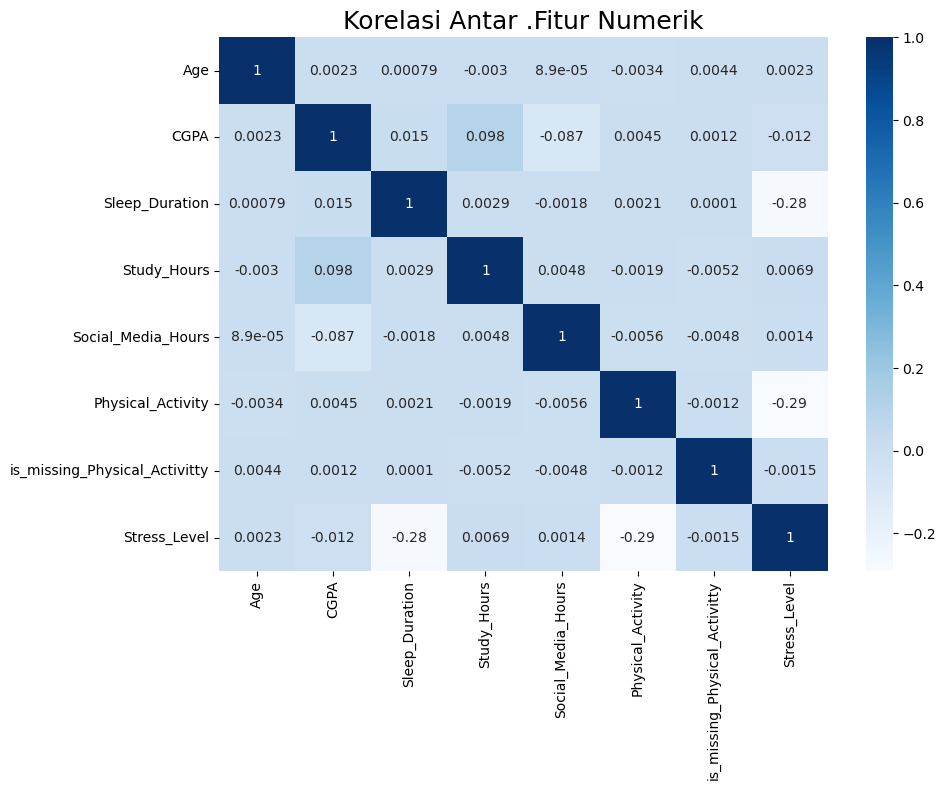

In [26]:
# Korelasi Antar Fitur Numerik (Heatmap)
plt.figure(figsize=(10, 8))

sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues')
plt.title('Korelasi Antar .Fitur Numerik', fontsize=18)

plt.tight_layout()
plt.show()

#### Insight (Korelasi Antar Fitur Numerik)
- Hampir semua pasangan fitur memiliki korelasi mendekati 0 yang berarti hubungan linear antar fitur **sangat lemah**
- Korelasi paling tinggi hanya sekitar **0.10** (CGPA vs Study_Hours) dan paling rendah sekitar **-0.088** (CGPA vs Social_Media_Hours), sehingga **tidak ada indikasi multicollinearity** yang signifikan

#### Keputusan (Action)
- Tidak ada fitur yang perlu di-drop karena multicollinearity

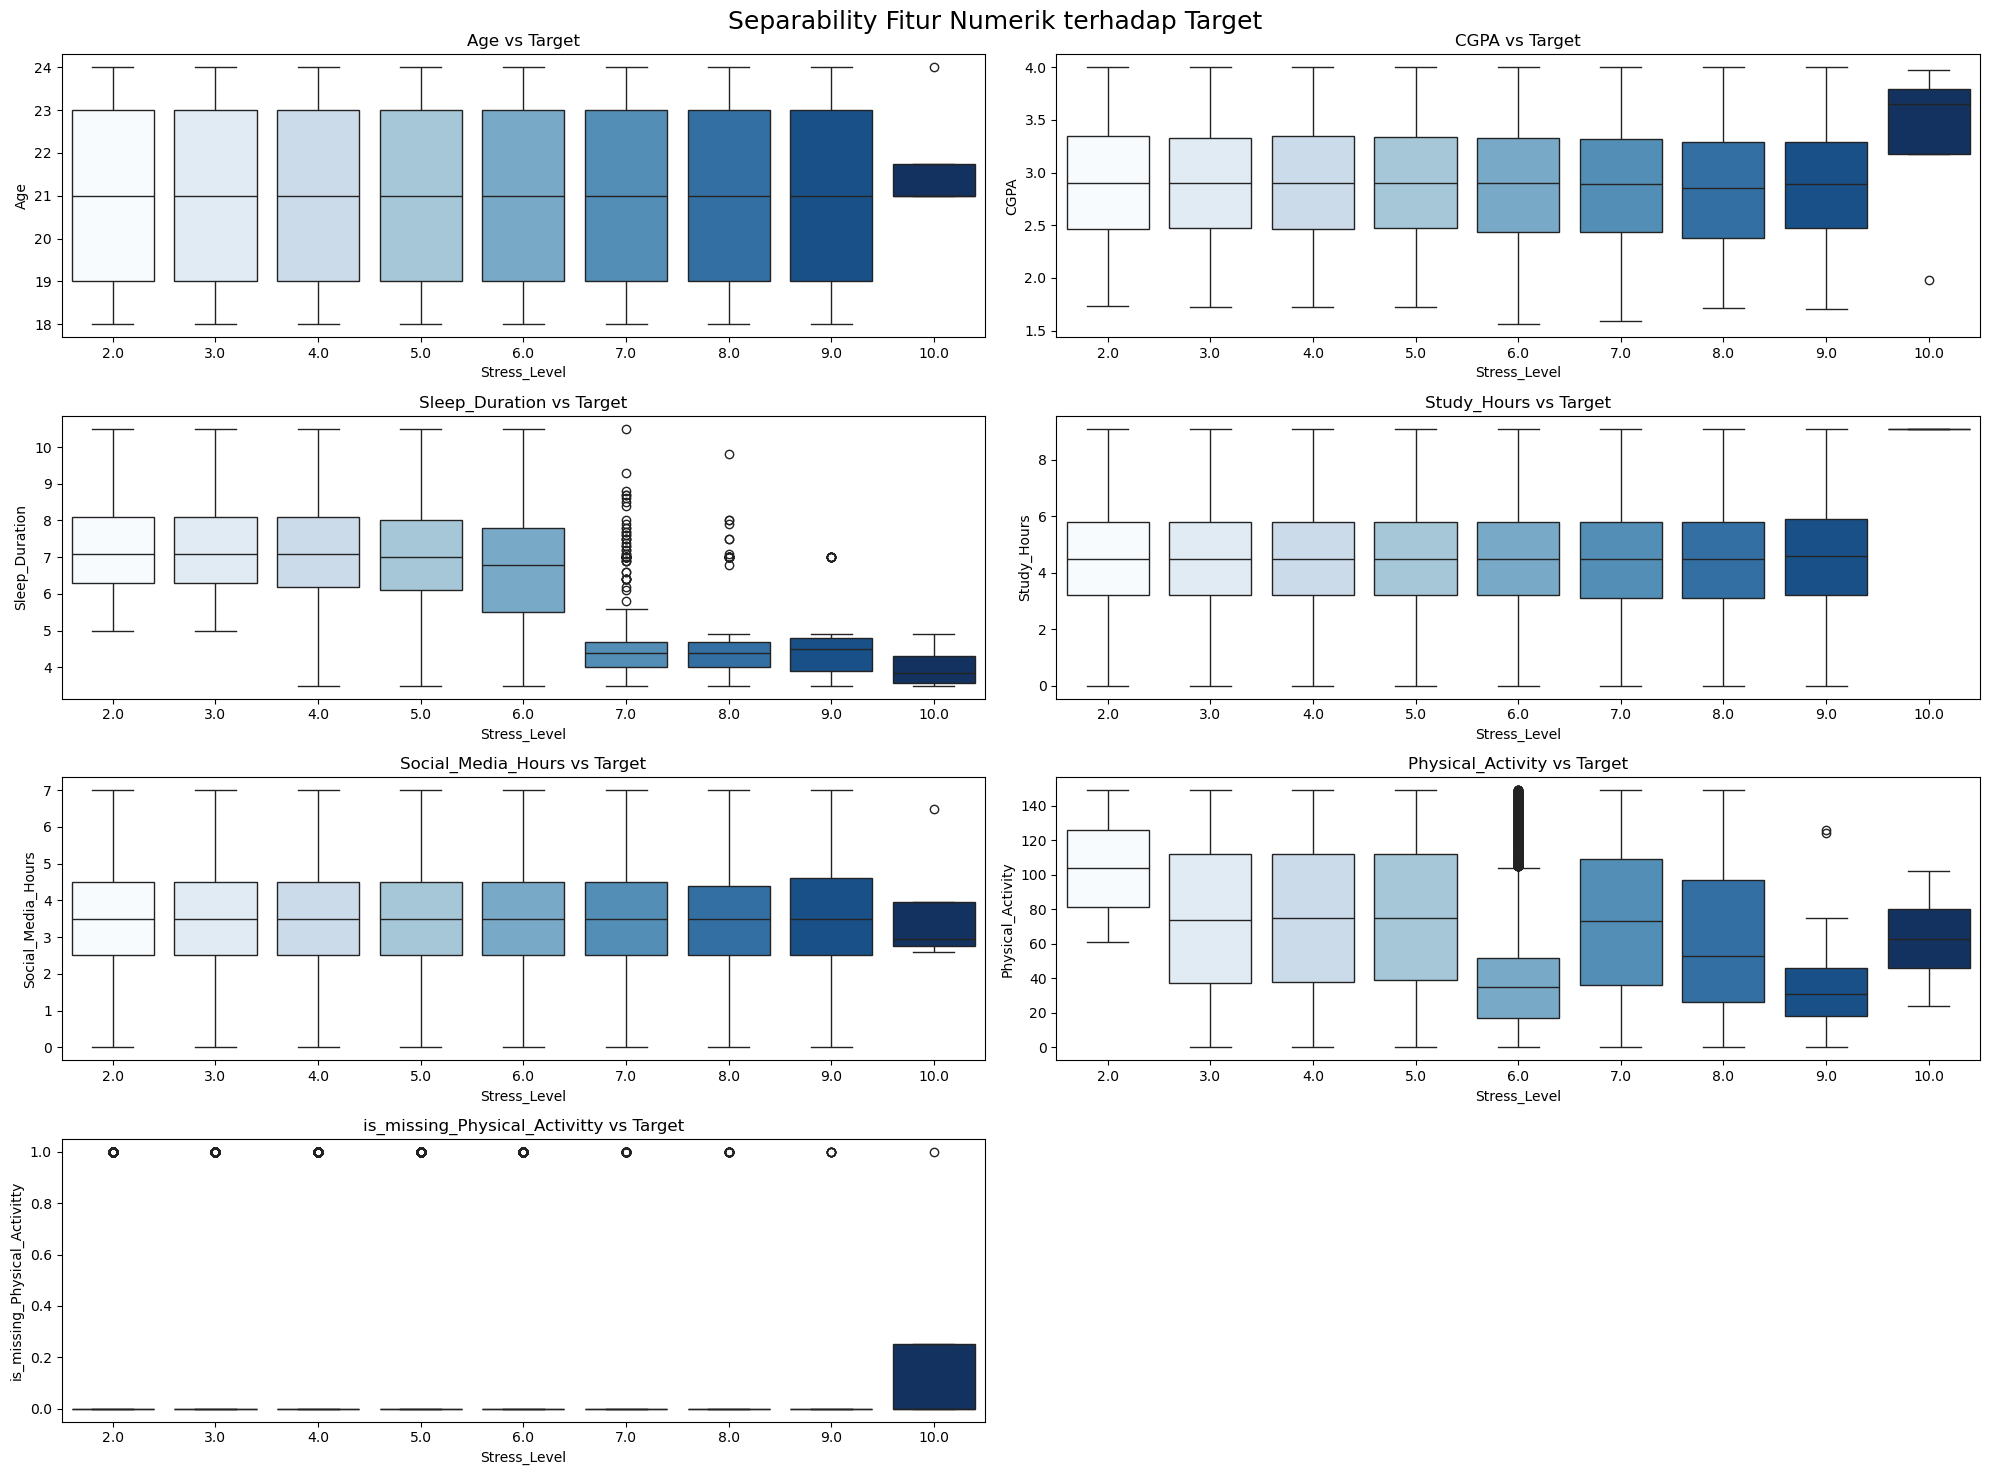

In [ ]:
# Separability Fitur Numerik terhadap Target (Boxplot)
plt.figure(figsize=(20, 15))

for i, col in enumerate(num_cols):
    plt.subplot(int(len(num_cols)/2)+1, 2, i+1)
    sns.boxplot(x=y, y=X[col], hue=y, legend=False, palette='Blues')
    plt.title(f'{col} vs Target')
    
plt.suptitle('Separability Fitur Numerik terhadap Target', fontsize=18)
plt.tight_layout()
plt.show()

#### Technical Insight
- **Sleep_Duration** menunjukkan separability paling kuat, semakin tinggi `Stress_Level`, durasi tidur juga turun sekitar 4–5 jam dibanding level rendah (2–6) yang cenderung lebih tinggi sekitar 6–8 jam. Overlap antar kelas relatif kecil, menunjukkan fitur ini sangat informatif
- **CGPA** memiliki sinyal terutama pada `Stress_Level = 10` terlihat memiliki median CGPA lebih tinggi, sementara kelas 2–9 cukup overlap
- **Age** hampir tidak membedakan target
- **Study_Hours** dan **Social_Media_Hours** ada perbedaan sedikit per kelas tapi overlap masih besar
- **Physical_Activity** menunjukkan variasi besar dan banyak outlier, ada perbedaan antar kelas tetapi overlap besar

#### Domain Insight 
- Pola **Sleep_Duration menurun saat stres meningkat** berarti stres yang lebih tinggi sering disebabkan kurang tiduratau istirahat yang tidak cukup
- **Physical_Activity** mengindikasikan perilaku aktivitas fisik mahasiswa bermacam-macam
- **CGPA tinggi pada stres ekstrem** bisa sebagai indikasi pressure akademik pada beberapa kelompok

#### Keputusan (Action)
- Prioritas fitur untuk modelling: `Sleep_Duration` (kuat), `Physical_Activity` (sedang)

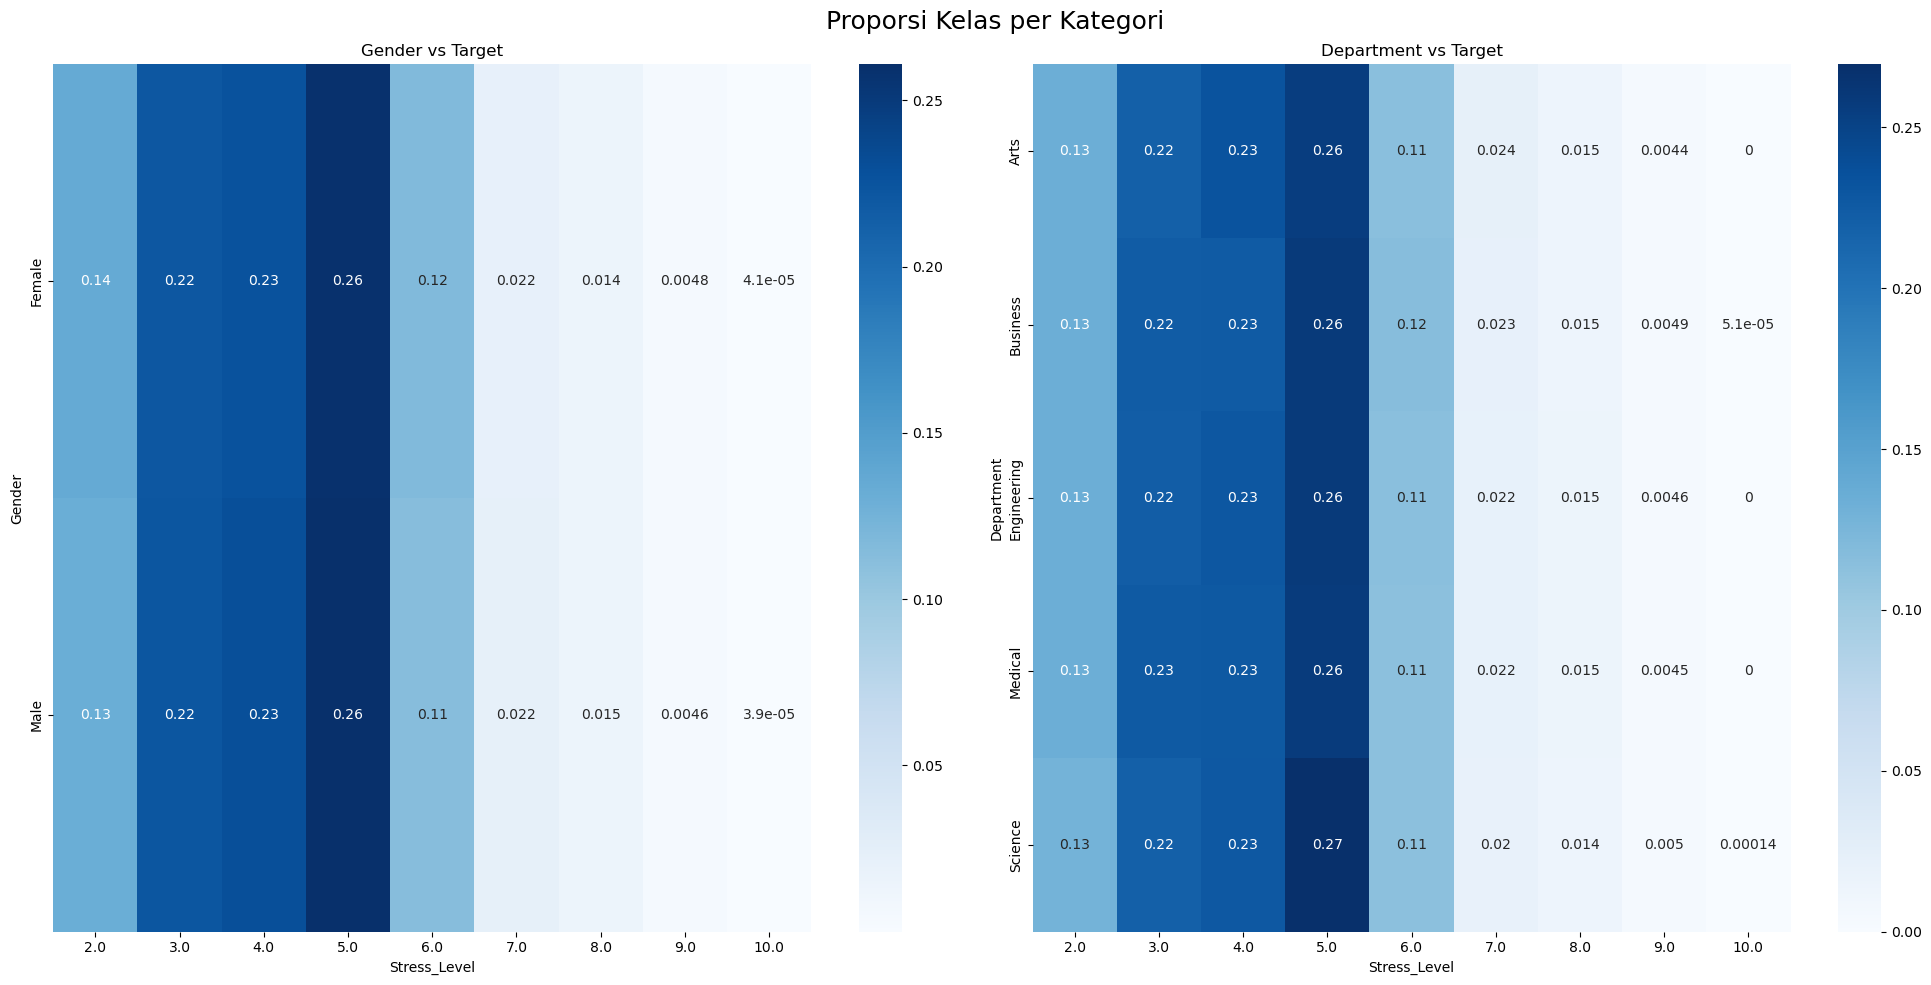

In [ ]:
# Proporsi Kelas per Kategori
plt.figure(figsize=(20,10))

for idx in range(len(cat_cols)):
    col = cat_cols[idx]
    ax = plt.subplot(int(len(cat_cols)/2), 2, idx+1)
    sns.heatmap(pd.crosstab(X[col], y, normalize='index'), annot=True, cmap='Blues')
    plt.title(f'{col} vs Target')
    
plt.suptitle('Proporsi Kelas per Kategori', fontsize=18)
plt.tight_layout()
plt.show()

#### Technical Insight
- Untuk **Gender**, pola proporsi Stress_Level antara **Male vs Female hampir identik** di semua level, berarti  ini memiliki separability rendah terhadap target
- Untuk **Department**, tiap jurusan juga menunjukkan proporsi yang **mirip**, fitur ini cenderung lemah membedakan target

#### Domain Insight
- Stres tidak berbeda secara signifikan berdasarkan jenis kelamin
- Pola Department yang mirip mengindikasikan kalo **tingkat stres relatif konsisten antar jurusan**, faktor stres mungkin bisa lebih dipengaruhi perilaku daripada identitas jurusan.

#### Keputusan Preprocessing (Action)
- Tidak terlihat kategori yang condong ke kelas tertentu

#### 📊 Identifikasi Outlier

In [ ]:
# Identifikasi Outlier dengan Metode IQR
def outlier_iqr(col: pd.Series):
    Q1 = col.quantile(0.25)
    Q3 = col.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = col[(col < lower_bound) | (col > upper_bound)].index.to_list()

    return outliers


# Identifikasi Outlier dengan Metode Z-Score
def outlier_zscore(col: pd.Series, thresh: float = 3.0):
    mean = col.mean()
    std = col.std()
    
    zscore = (col - mean) / std

    outliers = zscore[(zscore < -thresh) | (zscore > thresh)].index.to_list()

    return outliers


# Identifikasi Outlier dengan Metode MAD
def outlier_mad(col:pd.Series, thresh: float=3.0):
    median = col.median()

    mad = np.median(np.abs(col - median))

    modified_z = 0.6745 * (col -median) / mad

    outliers = modified_z[(modified_z < -thresh) | (modified_z > thresh)].index.to_list()

    return outliers


# Wrap Outlier
def outliers_wrapper(col: pd.Series):

    iqr = set(outlier_iqr(col))
    zscore = set(outlier_zscore(col))
    mad = set(outlier_mad(col))

    all_idx = iqr | zscore | mad
    results  = {
        'weak' : 0,
        'strong': 0,
        'extreme' : 0
    }

    for idx in all_idx:
        vote = (idx in iqr) + (idx in zscore) + (idx in mad)

        if vote == 1:
            results['weak'] += 1
        elif vote ==2:
            results['strong'] += 1
        elif vote == 3:
            results['extreme'] += 1

    return results

#### 📊 Scaling: Standard Scaler

In [ ]:
class StandardScaler:

    def __init__(self):
        self.mean = None
        self.std = None
        self.columns = None

    def fit(self, X):
        self.columns = X.columns

        X_np = X.values.astype(float)

        self.mean = X_np.mean(axis=0)
        self.std = X_np.std(axis=0)
        self.std = np.where(self.std == 0, 1e-8, self.std)

        return self
    
    def transform(self, X):
        X_np = X.values.astypr(float)

        X_scaled = (X_np - self.mean) / self.std

        return pd.DataFrame(X_scaled, columns=self.columns, index=X.index)
    
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

#### 📊 Normalization: Log Transform

In [ ]:
def auto_log_transform(col: pd.Series, eps: 1e-8):

    x = col.astype(float)

    min_val = x.min()

    if min_val > 0:
        return np.log(x + eps), 'log'
    elif min_val == 0:
        return np.log1p(x), 'log1p'
    elif min_val < 0:
        x_shifted = x + 1
        return np.log(x_shifted + eps), 'log'

#### 📊 Encoding: One-Hot Encoding

In [ ]:
def ohe_train_test(X_train: pd.DataFrame, X_test: pd.DataFrame, obj_col: pd.Series, col_name: str, drop_first=False):

    train_ohe = pd.get_dummies(obj_col, prefix=col_name, drop_first=drop_first)

    ohe_cols = train_ohe.columns

    test_series = X_test[col_name]
    test_ohe = pd.get_dummies(test_series, prefix=col_name, drop_first=drop_first).reindex(columns=ohe_cols, fill_value=0)

    train_ohe.index = X_train.index
    test_ohe.index = X_test.index

    return train_ohe, test_ohe

#### 📊 Splitting

In [ ]:
def stratified_split(X, y, test_size=0.2, random_state=42):

    rng = np.random.default_rng(random_state)

    train_idx = []
    test_idx = []

    classes = y.unique()
    for cls in classes:
        idx = np.where(y == cls)[0]

        rng.shuffle(idx)

        n_test = int(np.round(len(idx) * test_size))
        
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])

        rng.shuffle(train_idx)
        rng.shuffle(test_idx)

    X_train = X.iloc[train_idx]    
    X_test = X.iloc[test_idx]  
    
    y_train = y.iloc[train_idx]    
    y_test = y.iloc[test_idx]

    return X_train, X_test, y_train, y_test    

#### 📊 K-Fold Cross Validation

In [ ]:
def stratified_cv_indices(y, k=5, shuffle=True, random_state=42):

    y = np.asarray(y).ravel()
    n = y.shape[0]
    rng = np.random.default_rng(random_state)

    classes = y.unique()
    folds = [[] for _ in range(k)]

    for cls in classes:
        idx_c = np.where(y == cls)[0]

        if shuffle:
            rng.shuffle(idx_c)

        for i, idx_val in enumerate(idx_c):
            folds[i % k].append(idx_val)

    all_idx = np.arange(n)
    for i in range(k):
        test_idx = np.array(folds[i], dtype=int)
        test_idx.sort()

        train_mask = np.ones(n, dtype=bool)
        train_mask[test_idx] = False
        train_idx = all_idx[train_mask]

        yield train_idx, test_idx

def scores_cv(model_ctor, X, y, k=5, shuffle=True, random_state=42):
    
    X = np.asarray(X)
    y = np.asarray(y).ravel

    scores = []

    for tr, te in stratified_cv_indices(y, k=k, shuffle=shuffle, random_state=random_state):
        model = model_ctor()

        model.fit(X[tr], y[tr])
        pred = model.predict(X[te])
        scores.append(np.mean(pred == y[te]))

    scores = np.asarray(scores, dtype=float)

    return scores, float(np.mean(scores))